In [77]:
!pip install pandas
!pip install scikit-learn
!pip install scikit-optimize
!pip install matplotlib
!pip install imbalanced-learn
!pip install seaborn

In [1]:
# import libaries
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, make_scorer
import math
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from skopt import BayesSearchCV
from skopt.space import Integer, Categorical
from sklearn.inspection import permutation_importance
import seaborn as sns
from sklearn.metrics import fbeta_score

In [2]:
# read dataset
df = pd.read_csv("dataset/traffic_accidents.csv")

# Dataset characteristics

In [80]:
df.head()

,crash_date,traffic_control_device,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,roadway_surface_cond,road_defect,crash_type,...,most_severe_injury,injuries_total,injuries_fatal,injuries_incapacitating,injuries_non_incapacitating,injuries_reported_not_evident,injuries_no_indication,crash_hour,crash_day_of_week,crash_month
0,07/29/2023 01:00:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,TURNING,NOT DIVIDED,STRAIGHT AND LEVEL,UNKNOWN,UNKNOWN,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,13,7,7
1,08/13/2023 12:11:00 AM,TRAFFIC SIGNAL,CLEAR,"DARKNESS, LIGHTED ROAD",TURNING,FOUR WAY,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,2.0,0,1,8
2,12/09/2021 10:30:00 AM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,REAR END,T-INTERSECTION,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,10,5,12
3,08/09/2023 07:55:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,ANGLE,FOUR WAY,STRAIGHT AND LEVEL,DRY,NO DEFECTS,INJURY AND / OR TOW DUE TO CRASH,...,NONINCAPACITATING INJURY,5.0,0.0,0.0,5.0,0.0,0.0,19,4,8
4,08/19/2023 02:55:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,REAR END,T-INTERSECTION,STRAIGHT AND LEVEL,UNKNOWN,UNKNOWN,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,14,7,8


In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209306 entries, 0 to 209305
Data columns (total 24 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   crash_date                     209306 non-null  object 
 1   traffic_control_device         209306 non-null  object 
 2   weather_condition              209306 non-null  object 
 3   lighting_condition             209306 non-null  object 
 4   first_crash_type               209306 non-null  object 
 5   trafficway_type                209306 non-null  object 
 6   alignment                      209306 non-null  object 
 7   roadway_surface_cond           209306 non-null  object 
 8   road_defect                    209306 non-null  object 
 9   crash_type                     209306 non-null  object 
 10  intersection_related_i         209306 non-null  object 
 11  damage                         209306 non-null  object 
 12  prim_contributory_cause       

In [82]:
df.describe(include='all')

,crash_date,traffic_control_device,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,roadway_surface_cond,road_defect,crash_type,...,most_severe_injury,injuries_total,injuries_fatal,injuries_incapacitating,injuries_non_incapacitating,injuries_reported_not_evident,injuries_no_indication,crash_hour,crash_day_of_week,crash_month
count,209306,209306,209306,209306,209306,209306,209306,209306,209306,209306,...,209306,209306.000000,209306.000000,209306.000000,209306.000000,209306.000000,209306.000000,209306.000000,209306.000000,209306.000000
unique,189087,19,12,6,18,20,6,7,7,2,...,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,12/29/2020 05:00:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,TURNING,NOT DIVIDED,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,10,123944,164700,134109,64157,77753,204590,155905,171730,117376,...,154789,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.382717,0.001859,0.038102,0.221241,0.121516,2.244002,13.373047,4.144024,6.771822
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.799720,0.047502,0.233964,0.614960,0.450865,1.241175,5.603830,1.966864,3.427593
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,9.000000,2.000000,4.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,14.000000,4.000000,7.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,3.000000,17.000000,6.000000,10.000000


# Data preprocessing

In [3]:
df.drop(['crash_date'],axis='columns', inplace=True)
df.drop(['first_crash_type'],axis='columns', inplace=True)
df.drop(['crash_type'],axis='columns', inplace=True)
df.drop(['damage'],axis='columns', inplace=True)
df.drop(['prim_contributory_cause'],axis='columns', inplace=True)
df.drop(['num_units'],axis='columns', inplace=True)
df.drop(['most_severe_injury'],axis='columns', inplace=True)
df.drop(['injuries_fatal'],axis='columns', inplace=True)
df.drop(['injuries_incapacitating'],axis='columns', inplace=True)
df.drop(['injuries_non_incapacitating'],axis='columns', inplace=True)
df.drop(['injuries_reported_not_evident'],axis='columns', inplace=True)
df.drop(['injuries_no_indication'],axis='columns', inplace=True)


In [4]:
# Convert all categorical string to integers
for col in df.select_dtypes(include=['object']).columns:
    df[col], _ = pd.factorize(df[col])

# Output the DataFrame to a CSV file
df.to_csv("dataset/traffic_accidents_encoded.csv", index=False)


In [5]:
# Transform 'injuries_total' to 'Y' and 'N'
df['has_injuries'] = df['injuries_total'].apply(lambda x: 1 if x >= 1 else 0)

# Make 'has_injuries" as the target consequence to predict
df_y = df[['has_injuries']]
df_x = df.drop(['has_injuries'],axis='columns')
df_x = df_x.drop(columns=['injuries_total'])

# EDA

In [86]:
df_copy = pd.read_csv("dataset/traffic_accidents.csv")
df_copy['has_injuries'] = df_copy['injuries_total'].apply(lambda x: 1 if x >= 1 else 0)

C:\Users\HK\AppData\Local\Temp\ipykernel_24184\1794889645.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_copy2['crash_date'] = pd.to_datetime(df_copy2['crash_date'])


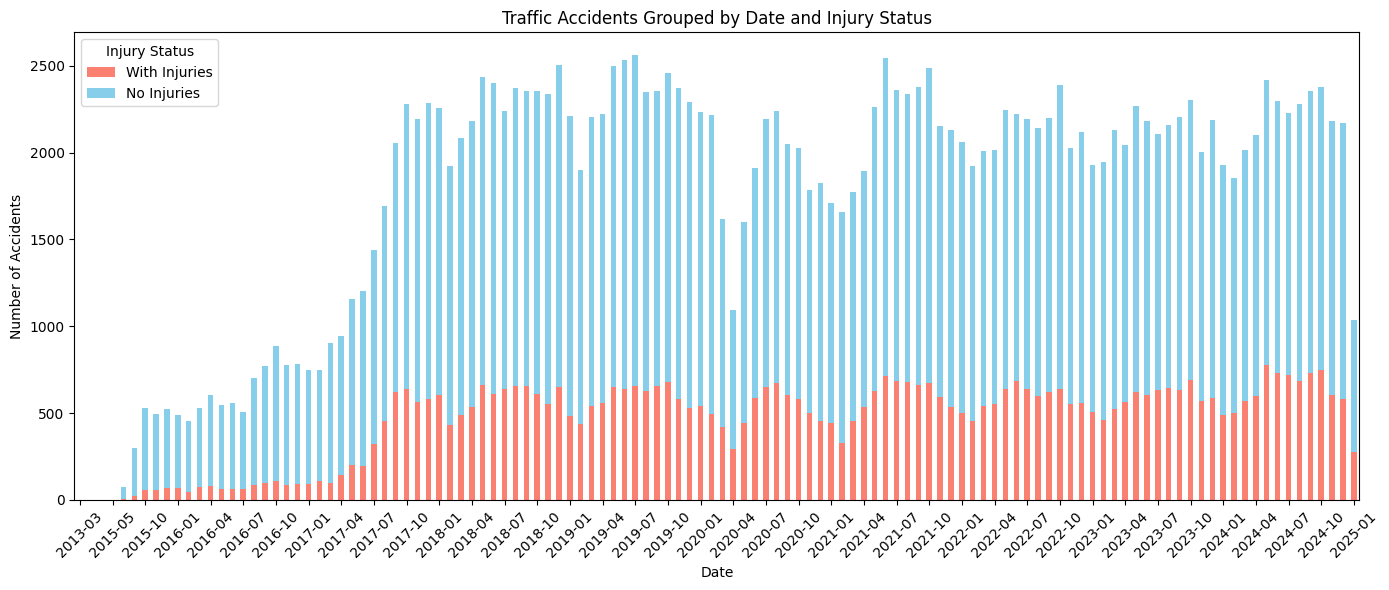

In [87]:
def plot_accident_histogram(df_original):
    df_copy2 = df_original.copy()
    df_copy2['crash_date'] = pd.to_datetime(df_copy2['crash_date'])
    df_copy2['month_year'] = df_copy2['crash_date'].dt.to_period('M').astype(str)
    df_copy2['injury_label'] = df_copy2['injuries_total'].apply(lambda x: 'No Injuries' if x == 0 else 'With Injuries')

    # Group by month and injury label
    grouped = df_copy2.groupby(['month_year', 'injury_label']).size().unstack(fill_value=0).sort_index()
    grouped = grouped[['With Injuries', 'No Injuries']]
    # Plot stacked bar chart
    grouped.plot(kind='bar', stacked=True, figsize=(14, 6), color=['salmon','skyblue'])

    plt.xticks(ticks=range(0, len(grouped.index), 3), labels=grouped.index[::3], rotation=45)
    plt.title("Traffic Accidents Grouped by Date and Injury Status")
    plt.xlabel("Date")
    plt.ylabel("Number of Accidents")
    plt.legend(title="Injury Status")
    plt.tight_layout()
    plt.show()

plot_accident_histogram(df_copy)


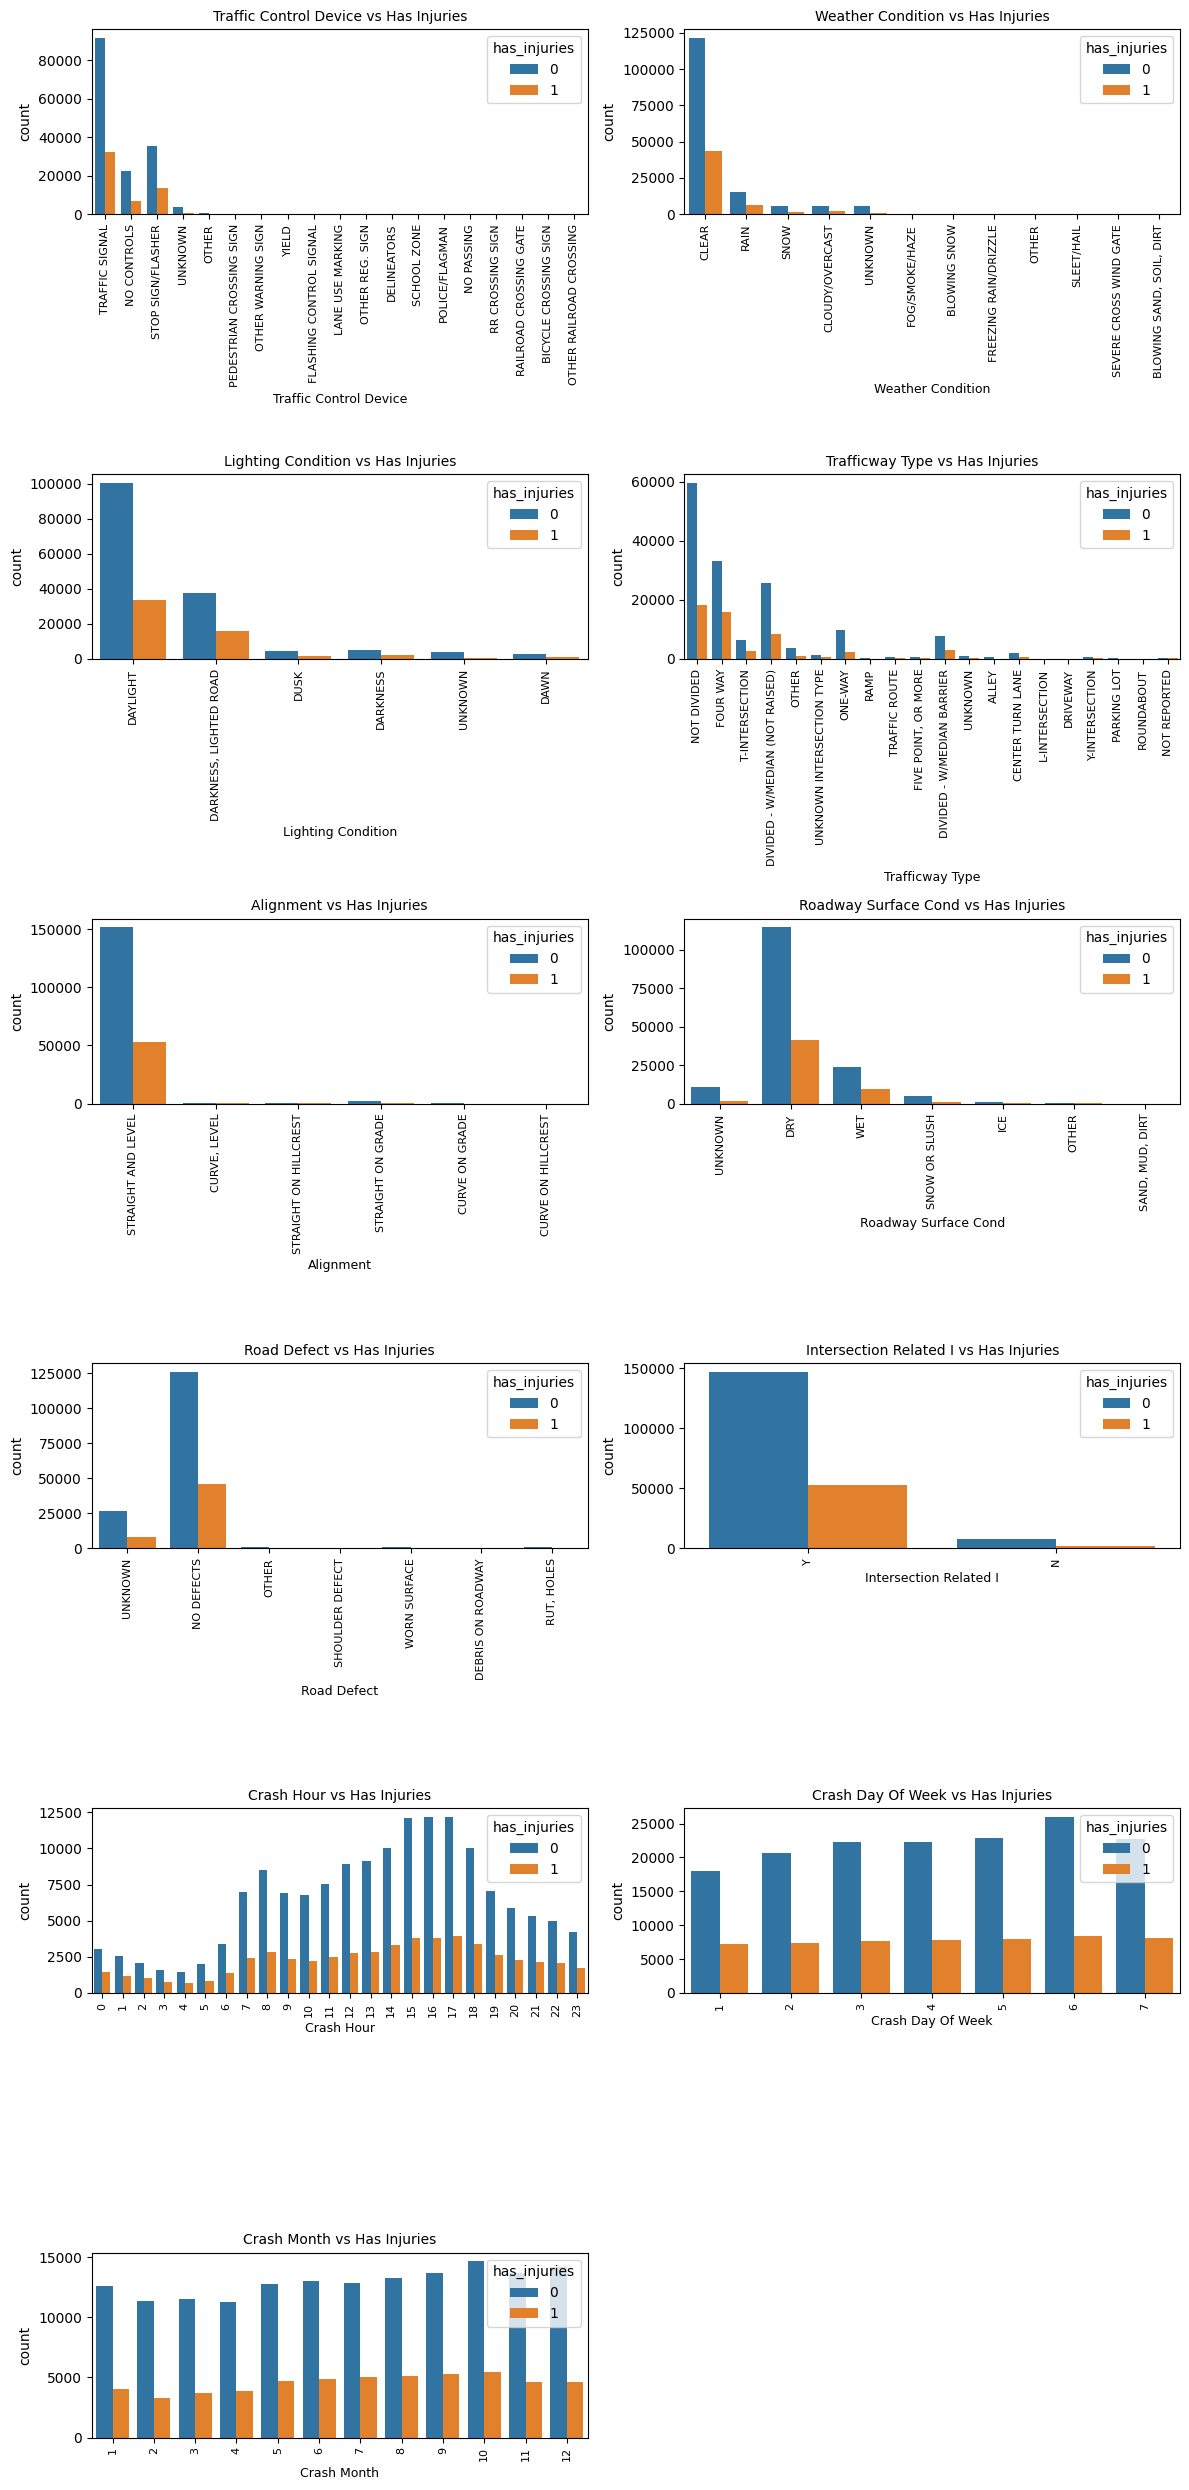

In [88]:
def analyze_injury_factors(df_original, features):
    fig, axs = plt.subplots(nrows=6, ncols=2, figsize=(12, 25))
    axs = axs.flatten()

    # Loop through features and plot
    for i, feature in enumerate(features):
        if feature in df_original.columns:
            sns.countplot(x=feature, hue='has_injuries', data=df_copy, ax=axs[i])
            formatted_name = feature.replace("_", " ").title()
            axs[i].set_title(f"{formatted_name} vs Has Injuries", fontsize=10)
            axs[i].set_xlabel(formatted_name, fontsize=9)
            axs[i].tick_params(axis='x', rotation=90, labelsize=8)

    axs[-1].set_visible(False)
    plt.tight_layout()
    plt.show()

analyze_injury_factors(df_copy, list(df_x.columns))

# Machine Learning

## Train/Test Split

In [6]:
# train, test = train_test_split(df, test_size=0.2, random_state=42)
x_train, x_test, y_train, y_test = train_test_split(df_x, df_y, test_size=0.2, random_state=42)

print (x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(167444, 11) (41862, 11) (167444, 1) (41862, 1)


In [90]:
# Check class distribution of "has_injuries" in the whole dataset
print('Class distribution of "has_injuries":')
print(df['has_injuries'].value_counts(), '\n')
# Check class distribution in train and test sets
print('y_train class distribution:')
print(y_train.value_counts(), '\n')
print('y_test class distribution:')
print(y_test.value_counts())

Class distribution of "has_injuries":
has_injuries
0    154789
1     54517
Name: count, dtype: int64 

y_train class distribution:
has_injuries
0               123958
1                43486
Name: count, dtype: int64 

y_test class distribution:
has_injuries
0               30831
1               11031
Name: count, dtype: int64


The above checking shows that there is potential problem of imbalance of data sample of "has_injuries".  The sample of having no injuries are three times more.  In later turning, it will try to balance the class to get a more accurate result.

In [91]:
# resampling data
smote = SMOTE(random_state=42)
x_resampled, y_resampled = smote.fit_resample(x_train, y_train)

print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:", y_resampled.value_counts())

Before SMOTE: has_injuries
0               123958
1                43486
Name: count, dtype: int64
After SMOTE: has_injuries
0               123958
1               123958
Name: count, dtype: int64


## Model 1 - Logistic Regression

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Logistic Regression model accuracy: 73.65%
Logistic Regression model confusion matrix:
 [[30831     0]
 [11031     0]]
Logistic Regression model F1 score: 0.42
Logistic Regression model F2 score: 0.00


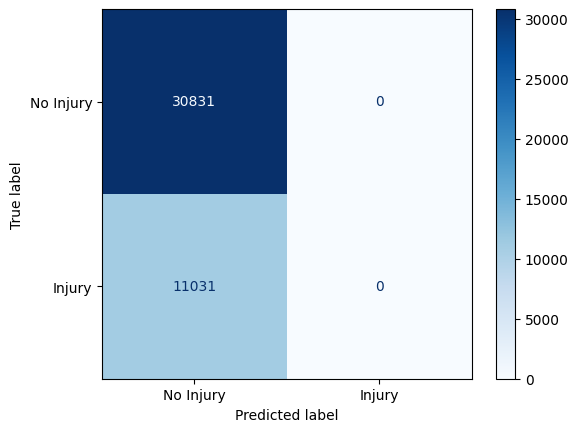

In [7]:
# Train logistic regression model
model_log_reg = LogisticRegression(random_state=0)
model_log_reg.fit(x_train, y_train)

# Evaluate model
accuracy = accuracy_score(y_test, model_log_reg.predict(x_test)) * 100
print(f"Logistic Regression model accuracy: {accuracy:.2f}%")

conf_mat = confusion_matrix(y_test, model_log_reg.predict(x_test))
print(f"Logistic Regression model confusion matrix:\n {conf_mat}")

f1 = f1_score(y_test, model_log_reg.predict(x_test), average='macro')
print(f"Logistic Regression model F1 score: {f1:.2f}")

f2 = fbeta_score(y_test, model_log_reg.predict(x_test), beta=2, pos_label=1)
print("Logistic Regression model F2 score: {:.2f}".format(f2))

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat, display_labels=['No Injury', 'Injury'])
disp.plot(cmap='Blues')


Feature Importance (Coefficient and Odds Ratio):
                   Feature  Coefficient  Odds Ratio
5     roadway_surface_cond     0.096397    1.101197
6              road_defect     0.062992    1.065018
4                alignment     0.042634    1.043556
2       lighting_condition     0.022790    1.023052
0   traffic_control_device     0.020195    1.020400
10             crash_month     0.010453    1.010508
3          trafficway_type    -0.002429    0.997574
8               crash_hour    -0.005056    0.994956
9        crash_day_of_week    -0.017251    0.982897
1        weather_condition    -0.065431    0.936664
7   intersection_related_i    -0.386713    0.679286


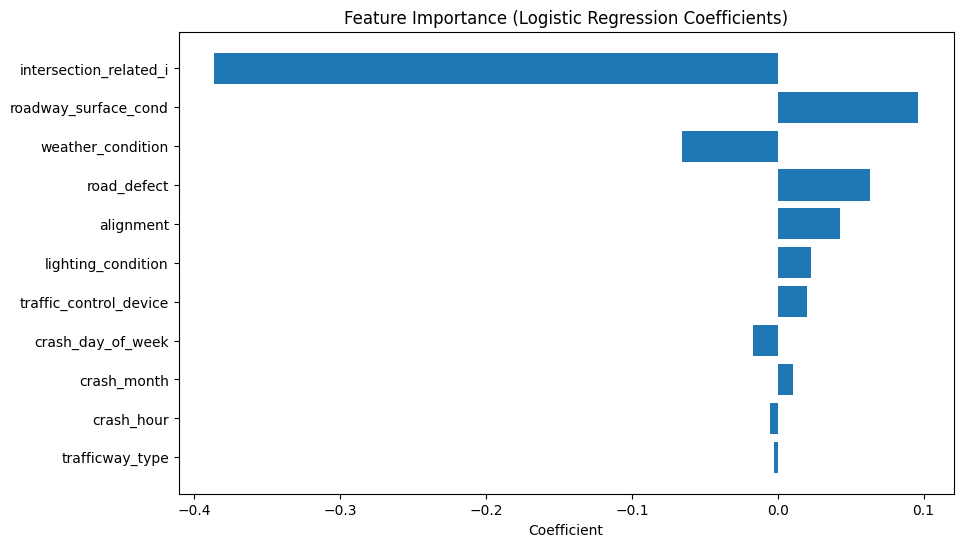

In [93]:
# Analyze the feature importance of each column in the model of Logistic Regression

coefficients = model_log_reg.coef_[0]
odds_ratios = np.exp(coefficients)

feature_importance = pd.DataFrame({
    'Feature': df_x.columns,
    'Coefficient': coefficients,
    'Odds Ratio': odds_ratios
})
print("\nFeature Importance (Coefficient and Odds Ratio):")
print(feature_importance.sort_values(by='Coefficient', ascending=False))

feature_importance_sorted = feature_importance.reindex(feature_importance['Coefficient'].abs().sort_values(ascending=False).index)

plt.figure(figsize=(10, 6))
plt.barh(feature_importance_sorted['Feature'], feature_importance_sorted['Coefficient'])
plt.xlabel('Coefficient')
plt.title('Feature Importance (Logistic Regression Coefficients)')
plt.gca().invert_yaxis()
plt.show()


Model 1 Tuning: Re-sampling and Hyperparameter

c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Logistic Regression model accuracy: 48.48%
Logistic Regression model confusion matrix:
 [[13523 17308]
 [ 4261  6770]]
Logistic Regression model F1 score: 0.47
Logistic Regression model F2 score: 0.50


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Logistic Regression model accuracy: 45.97%
Logistic Regression model confusion matrix:
 [[12267 18564]
 [ 4054  6977]]
Logistic Regression model F1 score: 0.45
Logistic Regression model F2 score: 0.50


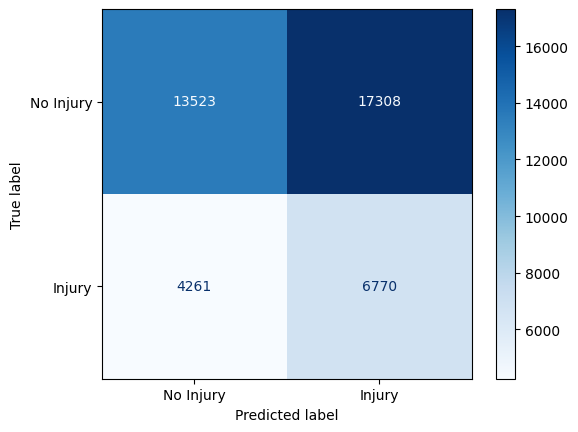

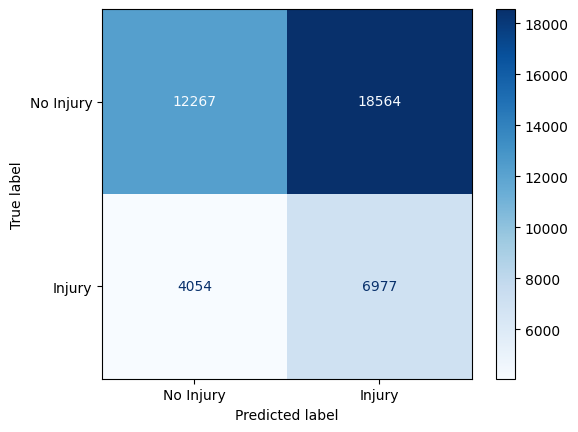

In [94]:
# Using class_weight='balanced' in LogisticRegression to handle class imbalance
model_log_reg_1 = LogisticRegression(random_state=42, class_weight='balanced')
model_log_reg_1.fit(x_train, y_train)

# Evaluate again
accuracy_1 = accuracy_score(y_test, model_log_reg_1.predict(x_test)) * 100
print(f"Logistic Regression model accuracy: {accuracy_1:.2f}%")

conf_mat_1 = confusion_matrix(y_test, model_log_reg_1.predict(x_test))
print(f"Logistic Regression model confusion matrix:\n {conf_mat_1}")

f1_1 = f1_score(y_test, model_log_reg_1.predict(x_test), average='macro')
print(f"Logistic Regression model F1 score: {f1_1:.2f}")

f2_1 = fbeta_score(y_test, model_log_reg_1.predict(x_test), beta=2, pos_label=1)
print("Logistic Regression model F2 score: {:.2f}".format(f2_1))


# Plot confusion matrix
disp_1 = ConfusionMatrixDisplay(confusion_matrix=conf_mat_1, display_labels=['No Injury', 'Injury'])
disp_1.plot(cmap='Blues')


# Using SMOTE resampling in LogisticRegression to handle class imbalance
model_log_reg_2 = LogisticRegression(random_state=42, class_weight='balanced')
model_log_reg_2.fit(x_resampled, y_resampled)

# Evaluate again
accuracy_2 = accuracy_score(y_test, model_log_reg_2.predict(x_test)) * 100
print(f"Logistic Regression model accuracy: {accuracy_2:.2f}%")

conf_mat_2 = confusion_matrix(y_test, model_log_reg_2.predict(x_test))
print(f"Logistic Regression model confusion matrix:\n {conf_mat_2}")

f1_2 = f1_score(y_test, model_log_reg_2.predict(x_test), average='macro')
print(f"Logistic Regression model F1 score: {f1_2:.2f}")

f2_2 = fbeta_score(y_test, model_log_reg_2.predict(x_test), beta=2, pos_label=1)
print("Logistic Regression model F2 score: {:.2f}".format(f2_2))

# Plot confusion matrix
disp_2 = ConfusionMatrixDisplay(confusion_matrix=conf_mat_2, display_labels=['No Injury', 'Injury'])
disp_2.plot(cmap='Blues')


It shows that both balancing weight class and SMOTE resampling do not improve but even worsen the prediction.  Let's try hyperparameter method Randomized Search.

Fitting 3 folds for each of 10 candidates, totalling 30 fits


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regr

[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.6s
[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   2.0s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ...................C=0.01, penalty=l2, solver=lbfgs; total time=   1.5s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ....................C=0.01, penalty=l2, solver=saga; total time=   1.8s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ....................C=0.01, penalty=l2, solver=saga; total time=   1.5s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ....................C=0.01, penalty=l2, solver=saga; total time=   1.3s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ....................C=0.1, penalty=l2, solver=lbfgs; total time=   1.7s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ....................C=0.1, penalty=l2, solver=lbfgs; total time=   1.6s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ....................C=0.1, penalty=l2, solver=lbfgs; total time=   1.0s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .....................C=0.1, penalty=l2, solver=saga; total time=   1.6s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .....................C=0.1, penalty=l2, solver=saga; total time=   1.6s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .....................C=0.1, penalty=l2, solver=saga; total time=   1.2s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ......................C=1, penalty=l2, solver=lbfgs; total time=   1.2s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ......................C=1, penalty=l2, solver=lbfgs; total time=   1.3s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ......................C=1, penalty=l2, solver=lbfgs; total time=   1.6s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .......................C=1, penalty=l2, solver=saga; total time=   1.3s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .......................C=1, penalty=l2, solver=saga; total time=   1.1s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .......................C=1, penalty=l2, solver=saga; total time=   1.6s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .....................C=10, penalty=l2, solver=lbfgs; total time=   1.1s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .....................C=10, penalty=l2, solver=lbfgs; total time=   1.2s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .....................C=10, penalty=l2, solver=lbfgs; total time=   1.1s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ......................C=10, penalty=l2, solver=saga; total time=   1.3s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ......................C=10, penalty=l2, solver=saga; total time=   1.1s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ......................C=10, penalty=l2, solver=saga; total time=   1.2s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ....................C=100, penalty=l2, solver=lbfgs; total time=   1.7s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ....................C=100, penalty=l2, solver=lbfgs; total time=   1.0s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END ....................C=100, penalty=l2, solver=lbfgs; total time=   1.0s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .....................C=100, penalty=l2, solver=saga; total time=   1.4s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .....................C=100, penalty=l2, solver=saga; total time=   1.0s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END .....................C=100, penalty=l2, solver=saga; total time=   1.1s


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Best Parameters: {'solver': 'lbfgs', 'penalty': 'l2', 'C': 0.01}
Logistic Regression accuracy (after Randomized Search tunning): 73.65%
Logistic Regression confusion matrix (after Randomized Search tunning):
 [[30831     0]
 [11031     0]]
Logistic Regression F1 score (after Randomized Search tunning): 0.42
Logistic Regression model F2 score (after Randomized Search tunning): 0.00


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


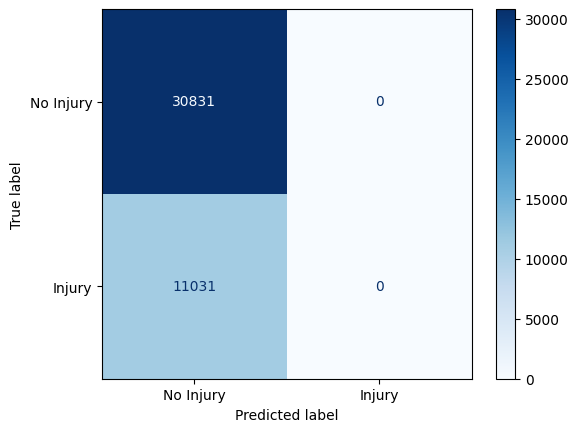

In [8]:
# Tunning Logistic Regression model using hyperparameters with RandomizedSearchCV
reg_log_param_dist = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['lbfgs', 'saga'],
    # 'max_iter': [100, 300, 500]
}
reg_log_randomized_search = RandomizedSearchCV(
    model_log_reg,
    reg_log_param_dist,
    scoring='f1_macro',
    cv=3,
    verbose=2,
    n_jobs=1
)

reg_log_randomized_search.fit(x_train, y_train)

reg_log_best_model = reg_log_randomized_search.best_estimator_
print("Best Parameters:", reg_log_randomized_search.best_params_)

# Evaluation after tunning with RandomizedSearchCV
reg_log_r_y_pred = reg_log_best_model.predict(x_test)
reg_log_r_acc = accuracy_score(y_test, reg_log_r_y_pred)*100
reg_log_r_conf_mat = confusion_matrix(y_test, reg_log_r_y_pred)
reg_log_r_f1 = f1_score(y_test, reg_log_r_y_pred, average='macro')
# reg_log_r_f2 = fbeta_score(y_test, model_log_reg.predict(x_test), beta=2, pos_label=1)
reg_log_r_f2 = fbeta_score(y_test, reg_log_r_y_pred, beta=2, pos_label=1)

# accuracy = accuracy_score(y_test, model_log_reg.predict(x_test)) * 100
print(f"Logistic Regression accuracy (after Randomized Search tunning): {reg_log_r_acc:.2f}%")
print(f"Logistic Regression confusion matrix (after Randomized Search tunning):\n {reg_log_r_conf_mat}")
print(f"Logistic Regression F1 score (after Randomized Search tunning): {reg_log_r_f1:.2f}")
print("Logistic Regression model F2 score (after Randomized Search tunning): {:.2f}".format(reg_log_r_f2))

# Plot confusion matrix
disp_3 = ConfusionMatrixDisplay(confusion_matrix=reg_log_r_conf_mat, display_labels=['No Injury', 'Injury'])
disp_3.plot(cmap='Blues')

Unexpectedly the performance of Randomized Serach is even worse than before tuning.  Now try another hyperparameter model Bayesian Optimization.

In [9]:
# Tunning Logistic Regression model using hyperparameters with Bayesian Optimization
search_space = {
    'C': (1e-6, 1e+6, 'log-uniform'),
    'penalty': ['l2'],
    'solver': ['lbfgs', 'saga']
}

opt = BayesSearchCV(
    LogisticRegression(max_iter=1000),
    search_spaces=search_space,
    n_iter=32,
    cv=3,
    scoring='accuracy',
    random_state=42
)

opt.fit(x_train, y_train)

print("Best parameters:", opt.best_params_)
print("Best score:", opt.best_score_)

# # Evaluate after hyperparameter tuning
# accuracy = accuracy_score(y_test, opt.predict(x_test)) * 100
# print(f"Logistic Regression model accuracy: {accuracy:.2f}%")

# conf_mat = confusion_matrix(y_test, opt.predict(x_test))
# print(f"Logistic Regression model confusion matrix:\n {conf_mat}")

# f1 = f1_score(y_test, opt.predict(x_test), average='macro')
# print(f"Logistic Regression model F1 score: {f1:.2f}")

# # Plot confusion matrix
# disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat, display_labels=['No Injury', 'Injury'])
# disp.plot(cmap='Blues')

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape 

Best parameters: OrderedDict([('C', 0.004771196592681151), ('penalty', 'l2'), ('solver', 'saga')])
Best score: 0.7403012350212492


The best score of Bayesian Optimization is 0.7403, which is slightly better than before-tuning at 73.65%

## Model 2 - Random Forest

c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Sample Data: {'traffic_control_device': 0, 'weather_condition': 0, 'lighting_condition': 0, 'trafficway_type': 0, 'alignment': 0, 'roadway_surface_cond': 1, 'road_defect': 1, 'intersection_related_i': 0, 'crash_hour': 15, 'crash_day_of_week': 6, 'crash_month': 6}
Predicted Injury Presence: No
Random Forest Classifier accuracy: 68.67%
Random Forest Classifier F1 score : 0.4941594375071878
Random Forest Classifier F2 score: 0.15


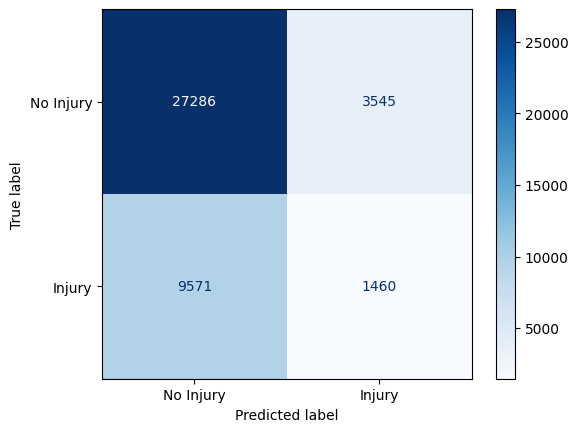

In [97]:
# Train Random Forest Classifier model
rf_model = RandomForestClassifier(n_estimators=100,random_state=42)
rf_model.fit(x_train, y_train)

# Evaluate the model
rf_y_pred = rf_model.predict(x_test)
rf_accuracy = accuracy_score(y_test, rf_y_pred ) * 100
rf_f1_score = f1_score(y_test, rf_y_pred, average='macro')
rf_f2_score = fbeta_score(y_test, rf_model.predict(x_test), beta=2, pos_label=1)


# Sample data
sample = x_test.iloc[0:1]
sample_pred = rf_model.predict(sample)
print(f"Sample Data: {sample.to_dict(orient='records')[0]}")
print(f"Predicted Injury Presence: {'Yes' if sample_pred[0] == 'Yes' else 'No'}")
print(f"Random Forest Classifier accuracy: {rf_accuracy:.2f}%")
print("Random Forest Classifier F1 score : {}".format(rf_f1_score))
print("Random Forest Classifier F2 score: {:.2f}".format(rf_f2_score))

# Compute confusion matrix
rf_conf_matrix = confusion_matrix(y_test, rf_y_pred)

disp = ConfusionMatrixDisplay(rf_conf_matrix , display_labels=['No Injury', 'Injury'])
disp.plot(cmap='Blues')

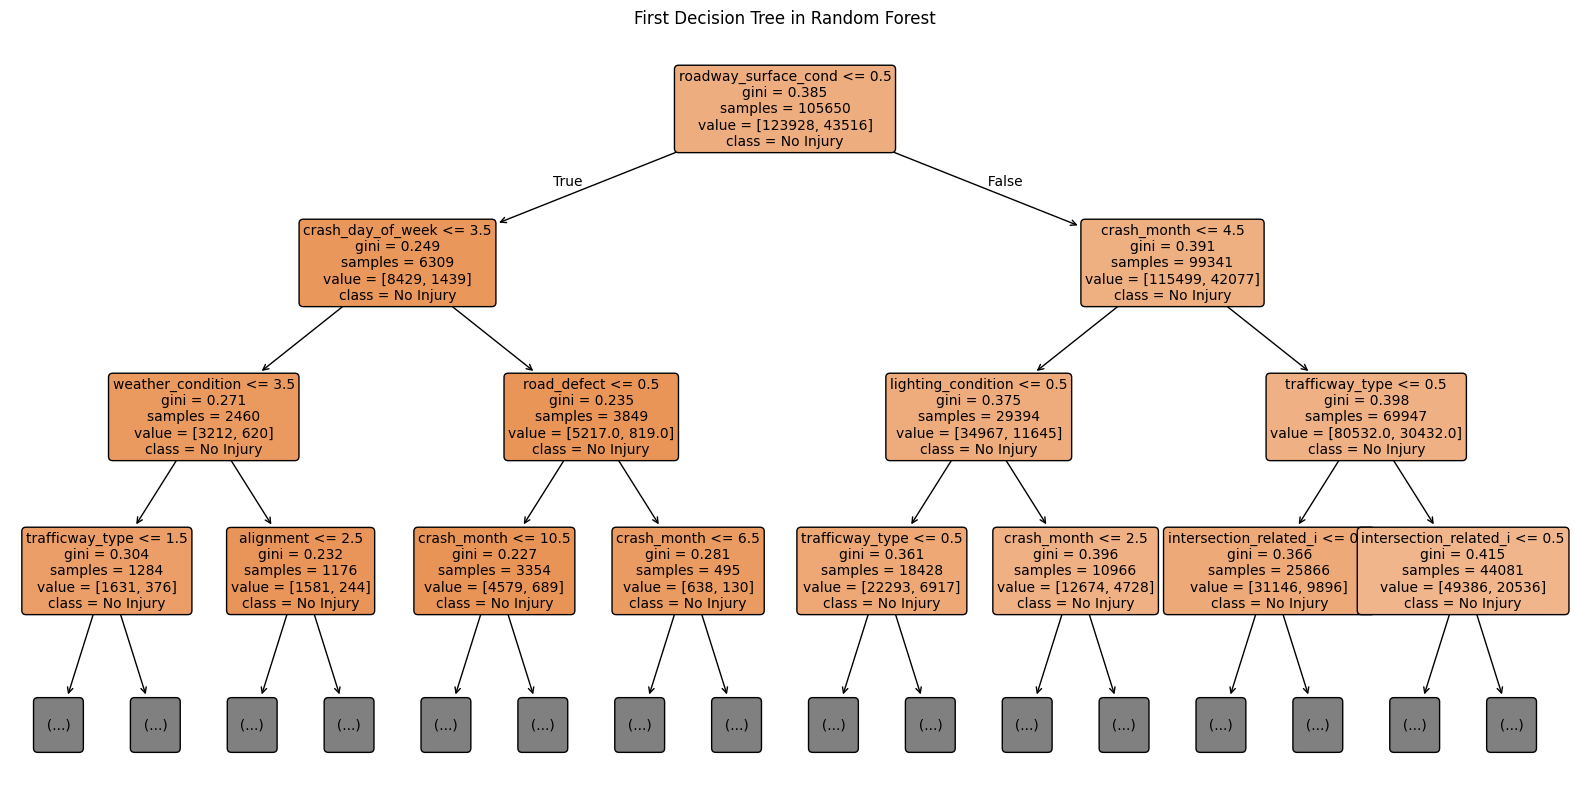

In [98]:
# Plot only the first decision tree from the forest
plt.figure(figsize=(20,10))
plot_tree(
    rf_model.estimators_[0],
    feature_names=x_train.columns,
    class_names=['No Injury', 'Injury'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=10
)
plt.title("First Decision Tree in Random Forest")
plt.show()

c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Variable: crash_hour           Importance: 0.26
Variable: crash_month          Importance: 0.2
Variable: crash_day_of_week    Importance: 0.18
Variable: trafficway_type      Importance: 0.09
Variable: traffic_control_device Importance: 0.07
Variable: weather_condition    Importance: 0.05
Variable: lighting_condition   Importance: 0.04
Variable: roadway_surface_cond Importance: 0.04
Variable: road_defect          Importance: 0.04
Variable: alignment            Importance: 0.02
Variable: intersection_related_i Importance: 0.01


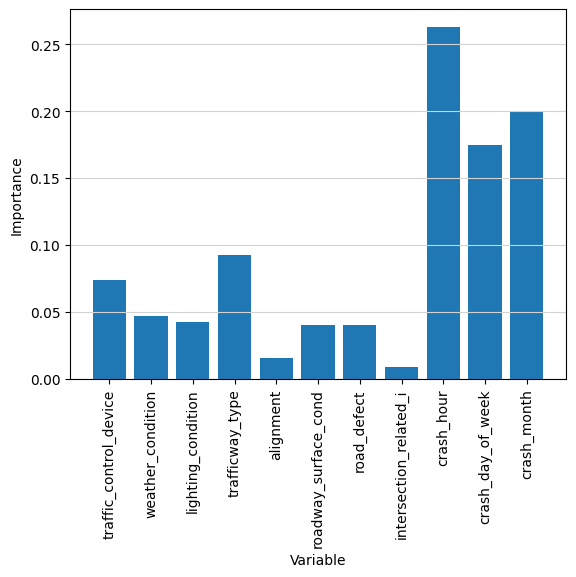

In [99]:
# Feature importances
rf_model.fit(df_x, df_y)
characteristics = df_x.columns
importances = list(rf_model.feature_importances_)
characteristics_importances = [(characteristic, round(importance, 2)) for characteristic, importance in zip(characteristics, importances)]
characteristics_importances = sorted(characteristics_importances, key = lambda x: x[1], reverse = True)
[print('Variable: {:20} Importance: {}'.format(*pair)) for pair in characteristics_importances];

plt.bar(characteristics, importances, orientation = 'vertical')
plt.xticks(rotation = 'vertical')
plt.ylabel('Importance')
plt.xlabel('Variable')
plt.grid(axis = 'y', color = '#D3D3D3', linestyle = 'solid')
plt.show()

In [100]:
# Train new model with selected features
rf_model_1= RandomForestClassifier(n_estimators=100, random_state=42)
rf_model_1.fit(x_train, y_train)

# Get feature importances
importances = rf_model.feature_importances_
feature_names = x_train.columns
feat_imp_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='importance', ascending=False)
selected_features = feat_imp_df[feat_imp_df['importance'] > 0.01]['feature'].tolist()

print("Selected features:\n", selected_features)

# Train new model with selected features
rf_selected = RandomForestClassifier(n_estimators=100, random_state=42)
rf_selected.fit(x_train[selected_features], y_train)


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Selected features:
 ['crash_hour', 'crash_month', 'crash_day_of_week', 'trafficway_type', 'traffic_control_device', 'weather_condition', 'lighting_condition', 'road_defect', 'roadway_surface_cond', 'alignment']


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Accuracy after feature selection: 68.64%
F1 score after feature selection: 0.4938
F2 score after feature selection: 0.15


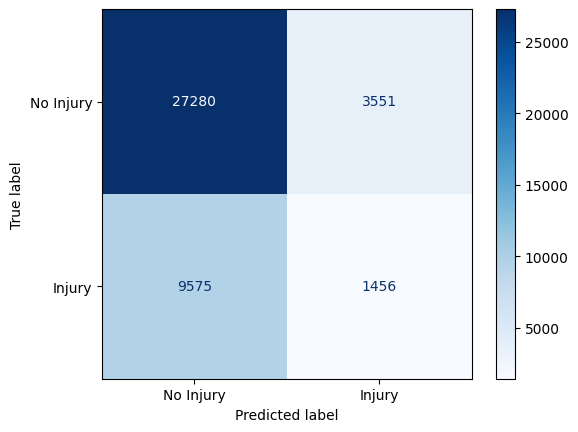

In [101]:
# Predict and evaluate on test data
rf_y_pred_1 = rf_selected.predict(x_test[selected_features])
rf_accuracy_1 = accuracy_score(y_test, rf_y_pred_1) * 100
rf_f1_score_1 = f1_score(y_test, rf_y_pred_1, average='macro')
rf_f2_score_1 = fbeta_score(y_test, rf_model_1.predict(x_test), beta=2, pos_label=1)

print(f"Accuracy after feature selection: {rf_accuracy_1:.2f}%")
print(f"F1 score after feature selection: {rf_f1_score_1:.4f}")
print("F2 score after feature selection: {:.2f}".format(rf_f2_score_1))

# Plot confusion matrix
rf_conf_mat_1 = confusion_matrix(y_test, rf_y_pred_1)
disp_1 = ConfusionMatrixDisplay(confusion_matrix=rf_conf_mat_1, display_labels=['No Injury', 'Injury'])
disp_1.plot(cmap='Blues')
plt.show()


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Best Hyperparameters: {'n_estimators': np.int64(117), 'min_samples_split': np.int64(2), 'min_samples_leaf': np.int64(10), 'max_features': 'sqrt', 'max_depth': np.int64(15), 'bootstrap': False}
Accuracy after RandomizedSearch: 73.64%
F1 score after RandomizedSearch: 0.4244642080698615
F2 score after RandomizedSearch: 0.15


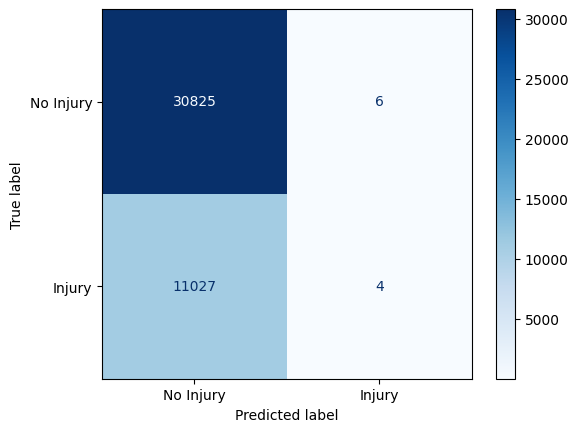

In [102]:
# Tunning Random Forest model using hyperparameters with RandomizedSearchCV
rf_model_2 = RandomForestClassifier(n_estimators=100,random_state=42)
rf_model_2.fit(x_train, y_train)

rf_param_dist_2 = {
    'n_estimators': np.arange(50, 150),
    'max_depth': [None] + list(np.arange(5, 31, 5)),
    'min_samples_split': np.arange(2, 11),
    'min_samples_leaf': np.arange(1, 11),
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False]
}

rf_random_search_2 = RandomizedSearchCV(
    estimator=rf_model_2,
    param_distributions=rf_param_dist_2,
    n_iter=20,          
    cv=3,              
    verbose=2,
    random_state=42,
    n_jobs=-1           
)


rf_random_search_2.fit(x_train, y_train)
rf_best_model = rf_random_search_2.best_estimator_
rf_y_pred_2 = rf_best_model.predict(x_test)

# Evaluation after tunning with RandomizedSearchCV
accuracy_2 = accuracy_score(y_test, rf_y_pred_2) * 100
rf_f1_score_2 = f1_score(y_test, rf_y_pred_2, average='macro')
rf_f2_score_2 = fbeta_score(y_test, rf_model_2.predict(x_test), beta=2, pos_label=1)

print("Best Hyperparameters:", rf_random_search_2.best_params_)
print(f"Accuracy after RandomizedSearch: {accuracy_2:.2f}%")
print("F1 score after RandomizedSearch: {}".format(rf_f1_score_2))
print("F2 score after RandomizedSearch: {:.2f}".format(rf_f2_score_2))

# Compute confusion matrix again
rf_conf_matrix_2 = confusion_matrix(y_test, rf_y_pred_2)

disp_2 = ConfusionMatrixDisplay(confusion_matrix=rf_conf_matrix_2, display_labels=['No Injury', 'Injury'])
disp_2.plot(cmap='Blues')
plt.show()

Fitting 5 folds for each of 20 candidates, totalling 100 fits


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
40 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
25 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "c:\Users\HK\A

Best parameters found: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30}
Best cross-validated F1 score: 0.48030935609778114
Test accuracy after cross-validation: 71.20%
Test F1 score after cross-validation: 0.4752
Test F2 score after cross-validation: 0.4906


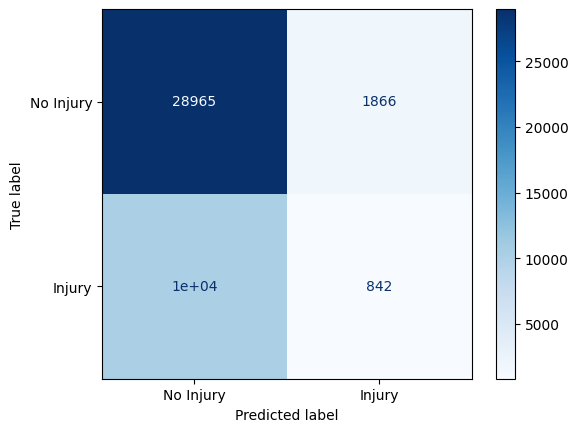

In [103]:
# Validate Random Forest hyperparameter tuning using cross-validation with F1 score as the scoring metric in RandomizedSearchCV
rf_model_3 = RandomForestClassifier(n_estimators=100,random_state=42)

rf_param_dist_3 = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt', 'log2']
}


# Use StratifiedKFold for balanced splits
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


# Use F1 score macro for balanced performance measure
scorer_3 = make_scorer(f1_score, average='macro')


# Set up RandomizedSearchCV with scoring and CV
random_search_3 = RandomizedSearchCV(
    estimator=rf_model_3,
    param_distributions=rf_param_dist_3,
    n_iter=20,
    scoring=scorer_3,
    cv=cv,
    verbose=2,
    random_state=42,
    n_jobs=-1
)


random_search_3.fit(x_train, y_train)


# Best parameters and cross-validated F1 score
print("Best parameters found:", random_search_3.best_params_)
print("Best cross-validated F1 score:", random_search_3.best_score_)


# Evaluate on test data with best estimator
best_rf_crossvalidate = random_search_3.best_estimator_
rf_y_pred_3 = best_rf_crossvalidate.predict(x_test)
rf_f2_score_3 = fbeta_score(y_test, rf_y_pred_3, beta=2, average='macro')

print(f"Test accuracy after cross-validation: {accuracy_score(y_test, rf_y_pred_3)*100:.2f}%")
print(f"Test F1 score after cross-validation: {f1_score(y_test, rf_y_pred_3, average='macro'):.4f}")
print(f"Test F2 score after cross-validation: {rf_f2_score_3:.4f}")

# Visualize confusion matrix

rf_conf_matrix_3 = confusion_matrix(y_test, rf_y_pred_3)

disp_3 = ConfusionMatrixDisplay(confusion_matrix=rf_conf_matrix_3, display_labels=['No Injury', 'Injury'])
disp_3.plot(cmap='Blues')

plt.show()

Fitting 3 folds for each of 20 candidates, totalling 60 fits


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Best Hyperparameters: {'n_estimators': np.int64(129), 'min_samples_split': np.int64(3), 'min_samples_leaf': np.int64(4), 'max_features': 'log2', 'max_depth': np.int64(20), 'bootstrap': True}
Accuracy with class_weight balanced: 60.07%
F1 score with class_weight balanced : 0.5377566876897433
F2 Score with class_weight balanced: 0.5425


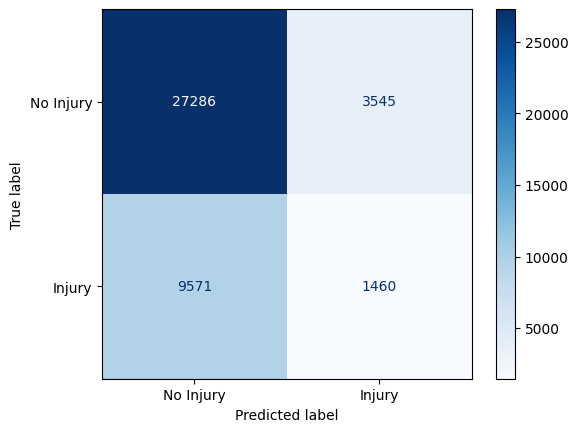

In [104]:
# Initialize model again with class_weight balanced
rf_model_4 = RandomForestClassifier(random_state=42, class_weight='balanced')

rf_param_dist_4 = {
    'n_estimators': np.arange(50, 150),
    'max_depth': [None] + list(np.arange(5, 31, 5)),
    'min_samples_split': np.arange(2, 11),
    'min_samples_leaf': np.arange(1, 11),
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False]
}

# Stratified splits
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Using macro F1 score for tuning
scorer_4 = make_scorer(f1_score, average='macro')

rf_random_search_4 = RandomizedSearchCV(
    estimator=rf_model_4,
    param_distributions=rf_param_dist_4,
    n_iter=20,
    cv=cv,
    scoring=scorer_4,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

rf_random_search_4.fit(x_train, y_train)
rf_best_model_bal = rf_random_search_4.best_estimator_
rf_y_pred_4 = rf_best_model_bal.predict(x_test)

# Evaluation
rf_accuracy_4 = accuracy_score(y_test, rf_y_pred_4) * 100
rf_f1_score_4 = f1_score(y_test, rf_y_pred_4, average='macro')
rf_f2_score_4 = fbeta_score(y_test, rf_y_pred_4, beta=2, average='macro')



print("Best Hyperparameters:", rf_random_search_4.best_params_)
print(f"Accuracy with class_weight balanced: {rf_accuracy_4:.2f}%")
print("F1 score with class_weight balanced : {}".format(rf_f1_score_4))
print(f"F2 Score with class_weight balanced: {rf_f2_score_4:.4f}")

# Visualize confusion matrix

rf_conf_matrix_4 = confusion_matrix(y_test, rf_y_pred_4)

disp_4 = ConfusionMatrixDisplay(confusion_matrix=rf_conf_matrix, display_labels=['No Injury', 'Injury'])
disp_4.plot(cmap='Blues')

plt.show()

Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fits
Fitting 3 folds for each of 1 candidates, totalling 3 fi

c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Best hyperparameters: OrderedDict({'bootstrap': False, 'max_depth': 30, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 65})
Test Accuracy with Bayesian Optimization: 66.33%
Test F1 Score with Bayesian Optimization: 0.5006
Test F2 Score with Bayesian Optimization: 0.5029


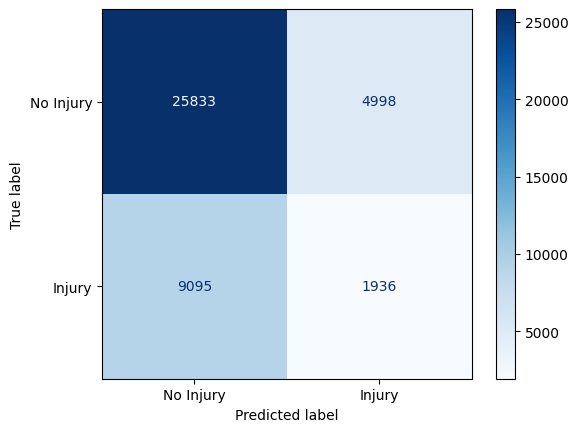

In [105]:
# Tuning with Bayesian Optimization

rf_model_5 = RandomForestClassifier(random_state=42)

rf_search_spaces = {
    'n_estimators': Integer(50, 150),
    'max_depth': Integer(5, 30),
    'min_samples_split': Integer(2, 10),
    'min_samples_leaf': Integer(1, 10),
    'max_features': Categorical(['sqrt', 'log2', None]),
    'bootstrap': Categorical([True, False])
}

rf_bayes_search = BayesSearchCV(
    estimator=rf_model_5,
    search_spaces=rf_search_spaces,
    n_iter=25,
    cv=3,
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1,
    verbose=2
)

rf_bayes_search.fit(x_train, y_train)

print("Best hyperparameters:", rf_bayes_search.best_params_)
rf_y_pred_5 = rf_bayes_search.best_estimator_.predict(x_test)

rf_accuracy_5 = accuracy_score(y_test, rf_y_pred_5) * 100
rf_f1_score_5 = f1_score(y_test, rf_y_pred_5, average='macro')
rf_f2_score_5 = fbeta_score(y_test, rf_y_pred_5, beta=2, average='macro')

print(f"Test Accuracy with Bayesian Optimization: {rf_accuracy_5:.2f}%")
print(f"Test F1 Score with Bayesian Optimization: {rf_f1_score_5:.4f}")
print(f"Test F2 Score with Bayesian Optimization: {rf_f2_score_5:.4f}")

rf_conf_matrix_5 = confusion_matrix(y_test, rf_y_pred_5)
disp = ConfusionMatrixDisplay(confusion_matrix=rf_conf_matrix_5, display_labels=['No Injury', 'Injury'])
disp.plot(cmap=plt.cm.Blues)
plt.show()


## Model 3 - Histogram-based Gradient Boosting Classification Tree

c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


HistGradientBoostingClassifier accuracy is : 73.68%
F1 score is : 0.43
F2 score is : 0.00


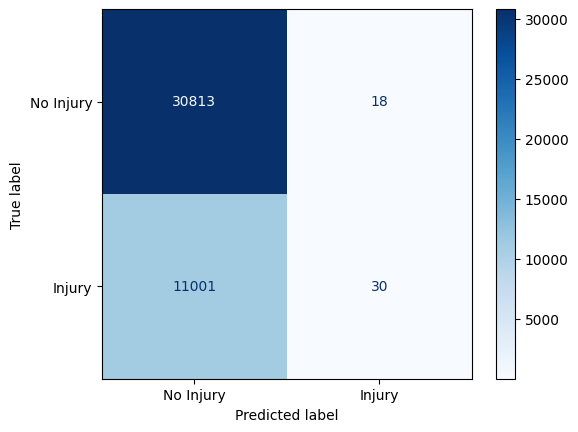

In [106]:
hgbc1 = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=300,
    random_state=100,
    max_features=0.5,
)

# Train the model
hgbc1.fit(x_train, y_train)

# Evaluate the model
hgbc_y_pred1 = hgbc1.predict(x_test)

hgbc_acc1 = accuracy_score(y_test, hgbc_y_pred1)
print("HistGradientBoostingClassifier accuracy is : {:.2f}%".format(hgbc_acc1 * 100))

hgbc_f1_score1 = f1_score(y_test, hgbc_y_pred1, average='macro')
print("F1 score is : {:.2f}".format(hgbc_f1_score1))

hgbc_f2_score1 = fbeta_score(y_test, hgbc_y_pred1, beta=2, pos_label=1)
print("F2 score is : {:.2f}".format(hgbc_f2_score1))

hgbc_cm1 = confusion_matrix(y_test, hgbc_y_pred1)

disp = ConfusionMatrixDisplay(confusion_matrix=hgbc_cm1, display_labels=['No Injury', 'Injury'])
disp.plot(cmap='Blues')

In [107]:
# Calculate permutation importance
result = permutation_importance(hgbc1, x_train, y_train, n_repeats=10, random_state=42)

# Sort features by importance
sorted_idx = result.importances_mean.argsort()
feature_names = x_train.columns
print("Feature Importances (Permutation):")
for i in sorted_idx[::-1]:
    print(f"{feature_names[i]}: {result.importances_mean[i]:.4f} +/- {result.importances_std[i]:.4f}")

Feature Importances (Permutation):
traffic_control_device: 0.0011 +/- 0.0001
trafficway_type: 0.0003 +/- 0.0000
crash_hour: 0.0003 +/- 0.0000
crash_month: 0.0003 +/- 0.0000
lighting_condition: 0.0002 +/- 0.0000
roadway_surface_cond: 0.0002 +/- 0.0000
crash_day_of_week: 0.0002 +/- 0.0000
alignment: 0.0001 +/- 0.0000
weather_condition: 0.0001 +/- 0.0000
road_defect: 0.0001 +/- 0.0000
intersection_related_i: 0.0000 +/- 0.0000


In [108]:
# hyperparameter tuning
hgbc = HistGradientBoostingClassifier(random_state=42)

# parameter distribution of randomized search
param_dist = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'max_features': [0.3, 0.5, 0.8, 1.0],
    'l2_regularization': [0.0, 0.1, 1.0],
    'max_iter': [100, 300, 500]
}
hgbc_randomized_search = RandomizedSearchCV(hgbc, param_dist, scoring='f1_macro', cv=3, verbose=2, n_jobs=1)

hgbc_randomized_search.fit(x_train, y_train)

hgbc_best_model = hgbc_randomized_search.best_estimator_
print("Best Parameters:", hgbc_randomized_search.best_params_)

hgbc_r_y_pred = hgbc_best_model.predict(x_test)
hgbc_r_acc = accuracy_score(y_test, hgbc_r_y_pred)
print("HistGradientBoostingClassifier accuracy is : {:.2f}%".format(hgbc_r_acc * 100))

hgbc_r_f1_score = f1_score(y_test, hgbc_r_y_pred, average='macro')
print("F1 score is : {:.2f}".format(hgbc_r_f1_score))

hgbc_r_f2_score = fbeta_score(y_test, hgbc_y_pred1, beta=2, pos_label=1)
print("F2 score is : {:.2f}".format(hgbc_r_f2_score))

Fitting 3 folds for each of 10 candidates, totalling 30 fits


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.1, max_depth=7, max_features=1.0, max_iter=300; total time=   0.4s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.1, max_depth=7, max_features=1.0, max_iter=300; total time=   0.4s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.1, max_depth=7, max_features=1.0, max_iter=300; total time=   0.5s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.0, learning_rate=0.01, max_depth=3, max_features=1.0, max_iter=300; total time=   1.2s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.0, learning_rate=0.01, max_depth=3, max_features=1.0, max_iter=300; total time=   1.2s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.0, learning_rate=0.01, max_depth=3, max_features=1.0, max_iter=300; total time=   1.2s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.05, max_depth=3, max_features=0.5, max_iter=500; total time=   1.0s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.05, max_depth=3, max_features=0.5, max_iter=500; total time=   1.1s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.05, max_depth=3, max_features=0.5, max_iter=500; total time=   1.1s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.05, max_depth=5, max_features=0.8, max_iter=100; total time=   0.6s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.05, max_depth=5, max_features=0.8, max_iter=100; total time=   0.7s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.05, max_depth=5, max_features=0.8, max_iter=100; total time=   0.7s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.1, learning_rate=0.1, max_depth=3, max_features=0.8, max_iter=300; total time=   0.7s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.1, learning_rate=0.1, max_depth=3, max_features=0.8, max_iter=300; total time=   0.9s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.1, learning_rate=0.1, max_depth=3, max_features=0.8, max_iter=300; total time=   0.5s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.05, max_depth=5, max_features=0.3, max_iter=300; total time=   0.8s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.05, max_depth=5, max_features=0.3, max_iter=300; total time=   1.0s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.05, max_depth=5, max_features=0.3, max_iter=300; total time=   0.9s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.1, learning_rate=0.05, max_depth=7, max_features=1.0, max_iter=100; total time=   0.7s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.1, learning_rate=0.05, max_depth=7, max_features=1.0, max_iter=100; total time=   0.7s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.1, learning_rate=0.05, max_depth=7, max_features=1.0, max_iter=100; total time=   0.7s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.1, max_depth=3, max_features=1.0, max_iter=100; total time=   0.4s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.1, max_depth=3, max_features=1.0, max_iter=100; total time=   0.4s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.1, max_depth=3, max_features=1.0, max_iter=100; total time=   0.4s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.1, learning_rate=0.05, max_depth=5, max_features=0.3, max_iter=300; total time=   1.1s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.1, learning_rate=0.05, max_depth=5, max_features=0.3, max_iter=300; total time=   1.2s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=0.1, learning_rate=0.05, max_depth=5, max_features=0.3, max_iter=300; total time=   1.0s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.01, max_depth=3, max_features=0.8, max_iter=300; total time=   1.2s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.01, max_depth=3, max_features=0.8, max_iter=300; total time=   1.2s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


[CV] END l2_regularization=1.0, learning_rate=0.01, max_depth=3, max_features=0.8, max_iter=300; total time=   1.3s


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Best Parameters: {'max_iter': 300, 'max_features': 1.0, 'max_depth': 7, 'learning_rate': 0.1, 'l2_regularization': 1.0}
HistGradientBoostingClassifier accuracy is : 73.66%
F1 score is : 0.43
F2 score is : 0.00


c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


HistGradientBoostingClassifier accuracy is : 53.89%
F1 score is : 0.51
F2 score is : 0.48


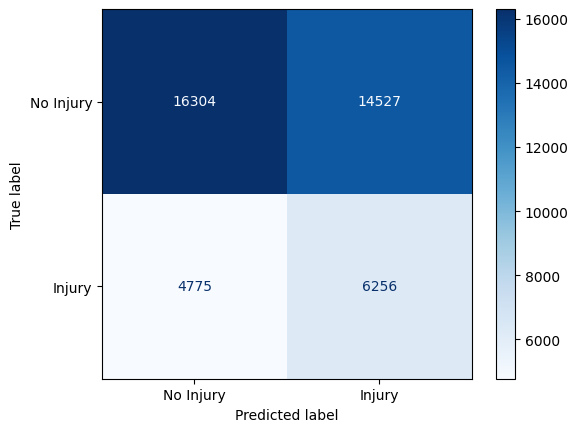

In [109]:
# Train the model with resampled data
hgbc2 = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=300,
    random_state=100,
    max_features=0.5,
    class_weight='balanced'
)

hgbc2.fit(x_resampled, y_resampled)

# Evaluate the model
hgbc_y_pred2 = hgbc2.predict(x_test)

hgbc_acc2 = accuracy_score(y_test, hgbc_y_pred2)
print("HistGradientBoostingClassifier accuracy is : {:.2f}%".format(hgbc_acc2 * 100))

hgbc_f1_score2 = f1_score(y_test, hgbc_y_pred2, average='macro')
print("F1 score is : {:.2f}".format(hgbc_f1_score2))

hgbc_f2_score2 = fbeta_score(y_test, hgbc_y_pred2, beta=2, pos_label=1)
print("F2 score is : {:.2f}".format(hgbc_f2_score2))

hgbc_cm2 = confusion_matrix(y_test, hgbc_y_pred2)

disp = ConfusionMatrixDisplay(confusion_matrix=hgbc_cm2, display_labels=['No Injury', 'Injury'])
disp.plot(cmap='Blues')

## Model Evaluation

In [110]:
# Model 1 - Logistic Regression
print('Logistic Regression Classification Report')
print('Originally Training Dataset:\n',classification_report(y_test, model_log_reg.predict(x_test)))
print('With Class_weight Balanced:\n',classification_report(y_test, model_log_reg_1 .predict(x_test)))
print('After Resampling:\n',classification_report(y_test, model_log_reg_2.predict(x_test)))
print('After RandomizedSearch:\n',classification_report(y_test, reg_log_best_model.predict(x_test)))


Logistic Regression Classification Report
Originally Training Dataset:
               precision    recall  f1-score   support

           0       0.74      1.00      0.85     30831
           1       0.00      0.00      0.00     11031

    accuracy                           0.74     41862
   macro avg       0.37      0.50      0.42     41862
weighted avg       0.54      0.74      0.62     41862

With Class_weight Balanced:
               precision    recall  f1-score   support

           0       0.76      0.44      0.56     30831
           1       0.28      0.61      0.39     11031

    accuracy                           0.48     41862
   macro avg       0.52      0.53      0.47     41862
weighted avg       0.63      0.48      0.51     41862

After Resampling:
               precision    recall  f1-score   support

           0       0.75      0.40      0.52     30831
           1       0.27      0.63      0.38     11031

    accuracy                           0.46     41862
   macro

c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HK\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

In [111]:
# Model 2 - Random Forest
print('Random Forest Classification Report')
print('Originally Training Dataset:\n',classification_report(y_test, rf_model.predict(x_test)))
print('After RandomizedSearch:\n',classification_report(y_test, rf_best_model.predict(x_test)))
print('After Cross-validation:\n',classification_report(y_test, best_rf_crossvalidate.predict(x_test)))
print('with Class_weight balanced:\n',classification_report(y_test, rf_best_model_bal.predict(x_test)))
print('After Bayesian Optimization:\n',classification_report(y_test, rf_bayes_search.best_estimator_.predict(x_test)))

Random Forest Classification Report
Originally Training Dataset:
               precision    recall  f1-score   support

           0       0.86      0.97      0.91     30831
           1       0.86      0.56      0.68     11031

    accuracy                           0.86     41862
   macro avg       0.86      0.76      0.79     41862
weighted avg       0.86      0.86      0.85     41862

After RandomizedSearch:
               precision    recall  f1-score   support

           0       0.74      1.00      0.85     30831
           1       0.40      0.00      0.00     11031

    accuracy                           0.74     41862
   macro avg       0.57      0.50      0.42     41862
weighted avg       0.65      0.74      0.62     41862

After Cross-validation:
               precision    recall  f1-score   support

           0       0.74      0.94      0.83     30831
           1       0.31      0.08      0.12     11031

    accuracy                           0.71     41862
   macro avg

In [112]:
# Model 3 - Histogram-based Gradient Boosting
print('Histogram-based Gradient Boosting Classification Report')
print('Originally Training Dataset:\n',classification_report(y_test, hgbc1.predict(x_test)))
print('After RandomizedSearch:\n',classification_report(y_test, hgbc_best_model.predict(x_test)))
print('After Resampling:\n',classification_report(y_test, hgbc2.predict(x_test)))

Histogram-based Gradient Boosting Classification Report
Originally Training Dataset:
               precision    recall  f1-score   support

           0       0.74      1.00      0.85     30831
           1       0.62      0.00      0.01     11031

    accuracy                           0.74     41862
   macro avg       0.68      0.50      0.43     41862
weighted avg       0.71      0.74      0.63     41862

After RandomizedSearch:
               precision    recall  f1-score   support

           0       0.74      1.00      0.85     30831
           1       0.52      0.00      0.01     11031

    accuracy                           0.74     41862
   macro avg       0.63      0.50      0.43     41862
weighted avg       0.68      0.74      0.63     41862

After Resampling:
               precision    recall  f1-score   support

           0       0.77      0.53      0.63     30831
           1       0.30      0.57      0.39     11031

    accuracy                           0.54     4186

# Application and Prediction

In [10]:
# Function to allow user input for prediction
def predict_injury(model, feature_names):
    print("Enter values for the road conditions:")
    input_data = []
    for col in feature_names:
        val = input(f"{col}: ")
        # Try to convert to float, else keep as int
        try:
            val = float(val)
        except ValueError:
            val = int(val)
        input_data.append(val)
    # Convert to DataFrame for prediction
    X_new = pd.DataFrame([input_data], columns=feature_names)
    pred = model.predict(X_new)[0]
    result = "Injury" if pred == 1 else "No Injury"
    print(f"Prediction: {result}")



factorize_maps = {}
for col in df.select_dtypes(include=['object']).columns:
    df[col], uniques = pd.factorize(df[col])
    factorize_maps[col] = uniques

print ("Refer to the below index mapping when entering categorical values:\n")
print ("Column: traffic_control_device")
print ("{'TRAFFIC SIGNAL': 0, 'NO CONTROLS': 1, 'STOP SIGN/FLASHER': 2, 'UNKNOWN': 3, 'OTHER': 4, 'PEDESTRIAN CROSSING SIGN': 5, 'OTHER WARNING SIGN': 6, 'YIELD': 7, 'FLASHING CONTROL SIGNAL': 8, 'LANE USE MARKING': 9, 'OTHER REG. SIGN': 10, 'DELINEATORS': 11, 'SCHOOL ZONE': 12, 'POLICE/FLAGMAN': 13, 'NO PASSING': 14, 'RR CROSSING SIGN': 15, 'RAILROAD CROSSING GATE': 16, 'BICYCLE CROSSING SIGN': 17, 'OTHER RAILROAD CROSSING': 18}")
print ("\nColumn: weather_condition")
print ("{'CLEAR': 0, 'RAIN': 1, 'SNOW': 2, 'CLOUDY/OVERCAST': 3, 'UNKNOWN': 4, 'FOG/SMOKE/HAZE': 5, 'BLOWING SNOW': 6, 'FREEZING RAIN/DRIZZLE': 7, 'OTHER': 8, 'SLEET/HAIL': 9, 'SEVERE CROSS WIND GATE': 10, 'BLOWING SAND, SOIL, DIRT': 11}")
print ("\nColumn: lighting_condition")
print ("{'DAYLIGHT': 0, 'DARKNESS, LIGHTED ROAD': 1, 'DUSK': 2, 'DARKNESS': 3, 'UNKNOWN': 4, 'DAWN': 5}")
print ("\nColumn: trafficway_type")
print ("{'NOT DIVIDED': 0, 'FOUR WAY': 1, 'T-INTERSECTION': 2, 'DIVIDED - W/MEDIAN (NOT RAISED)': 3, 'OTHER': 4, 'UNKNOWN INTERSECTION TYPE': 5, 'ONE-WAY': 6, 'RAMP': 7, 'TRAFFIC ROUTE': 8, 'FIVE POINT, OR MORE': 9, 'DIVIDED - W/MEDIAN BARRIER': 10, 'UNKNOWN': 11, 'ALLEY': 12, 'CENTER TURN LANE': 13, 'L-INTERSECTION': 14, 'DRIVEWAY': 15, 'Y-INTERSECTION': 16, 'PARKING LOT': 17, 'ROUNDABOUT': 18, 'NOT REPORTED': 19}")
print ("\nColumn: alignment")
print ("{'STRAIGHT AND LEVEL': 0, 'CURVE, LEVEL': 1, 'STRAIGHT ON HILLCREST': 2, 'STRAIGHT ON GRADE': 3, 'CURVE ON GRADE': 4, 'CURVE ON HILLCREST': 5}")
print ("\nColumn: roadway_surface_cond")
print ("{'UNKNOWN': 0, 'DRY': 1, 'WET': 2, 'SNOW OR SLUSH': 3, 'ICE': 4, 'OTHER': 5, 'SAND, MUD, DIRT': 6}")
print ("\nColumn: road_defect")
print ("{'UNKNOWN': 0, 'NO DEFECTS': 1, 'OTHER': 2, 'SHOULDER DEFECT': 3, 'WORN SURFACE': 4, 'DEBRIS ON ROADWAY': 5, 'RUT, HOLES': 6}")
print ("\nColumn: intersection_related_i")
print ("{'Y': 0, 'N': 1}\n")

# Demo:
predict_injury(model_log_reg, df_x.columns)

Refer to the below index mapping when entering categorical values:

Column: traffic_control_device
{'TRAFFIC SIGNAL': 0, 'NO CONTROLS': 1, 'STOP SIGN/FLASHER': 2, 'UNKNOWN': 3, 'OTHER': 4, 'PEDESTRIAN CROSSING SIGN': 5, 'OTHER WARNING SIGN': 6, 'YIELD': 7, 'FLASHING CONTROL SIGNAL': 8, 'LANE USE MARKING': 9, 'OTHER REG. SIGN': 10, 'DELINEATORS': 11, 'SCHOOL ZONE': 12, 'POLICE/FLAGMAN': 13, 'NO PASSING': 14, 'RR CROSSING SIGN': 15, 'RAILROAD CROSSING GATE': 16, 'BICYCLE CROSSING SIGN': 17, 'OTHER RAILROAD CROSSING': 18}

Column: weather_condition
{'CLEAR': 0, 'RAIN': 1, 'SNOW': 2, 'CLOUDY/OVERCAST': 3, 'UNKNOWN': 4, 'FOG/SMOKE/HAZE': 5, 'BLOWING SNOW': 6, 'FREEZING RAIN/DRIZZLE': 7, 'OTHER': 8, 'SLEET/HAIL': 9, 'SEVERE CROSS WIND GATE': 10, 'BLOWING SAND, SOIL, DIRT': 11}

Column: lighting_condition
{'DAYLIGHT': 0, 'DARKNESS, LIGHTED ROAD': 1, 'DUSK': 2, 'DARKNESS': 3, 'UNKNOWN': 4, 'DAWN': 5}

Column: trafficway_type
{'NOT DIVIDED': 0, 'FOUR WAY': 1, 'T-INTERSECTION': 2, 'DIVIDED - W/M

In [11]:
# A GUI version

import tkinter as tk
from tkinter import messagebox

def predict_injury_gui(model, feature_names, factorize_maps=None):
    def on_predict():
        input_data = []
        for idx, col in enumerate(feature_names):
            val = entries[idx].get()
            try:
                val = float(val)
            except ValueError:
                val = int(val)
            input_data.append(val)
        X_new = pd.DataFrame([input_data], columns=feature_names)
        pred = model.predict(X_new)[0]
        result = "High risk of Injurable traffic accident  Priority should be given to fix this road." if pred == 1 else "Low Risk of Injurable traffic accident"
        messagebox.showinfo("Prediction Result", f"Prediction: {result}")

    root = tk.Tk()
    root.title("Traffic Injury Prediction")

    entries = []
    for idx, col in enumerate(feature_names):
        label_text = col
        if factorize_maps and col in factorize_maps:
            mapping = {i: v for i, v in enumerate(factorize_maps[col])}
            label_text += f" (index: {mapping})"
        tk.Label(root, text=label_text).grid(row=idx, column=0, sticky="w")
        entry = tk.Entry(root)
        entry.grid(row=idx, column=1)
        entries.append(entry)

    predict_btn = tk.Button(root, text="Predict", command=on_predict)
    predict_btn.grid(row=len(feature_names), column=0, columnspan=2)

    description = (
        "Refer to the below index mapping when entering categorical values:\n"
        "Column: traffic_control_device\n"
        "{'TRAFFIC SIGNAL': 0, 'NO CONTROLS': 1, 'STOP SIGN/FLASHER': 2, 'UNKNOWN': 3, 'OTHER': 4, 'PEDESTRIAN CROSSING SIGN': 5, 'OTHER WARNING SIGN': 6, 'YIELD': 7, 'FLASHING CONTROL SIGNAL': 8, 'LANE USE MARKING': 9, 'OTHER REG. SIGN': 10, 'DELINEATORS': 11, 'SCHOOL ZONE': 12, 'POLICE/FLAGMAN': 13, 'NO PASSING': 14, 'RR CROSSING SIGN': 15, 'RAILROAD CROSSING GATE': 16, 'BICYCLE CROSSING SIGN': 17, 'OTHER RAILROAD CROSSING': 18}\n"
        "\nColumn: weather_condition\n"
        "{'CLEAR': 0, 'RAIN': 1, 'SNOW': 2, 'CLOUDY/OVERCAST': 3, 'UNKNOWN': 4, 'FOG/SMOKE/HAZE': 5, 'BLOWING SNOW': 6, 'FREEZING RAIN/DRIZZLE': 7, 'OTHER': 8, 'SLEET/HAIL': 9, 'SEVERE CROSS WIND GATE': 10, 'BLOWING SAND, SOIL, DIRT': 11}\n"
        "\nColumn: lighting_condition\n"
        "{'DAYLIGHT': 0, 'DARKNESS, LIGHTED ROAD': 1, 'DUSK': 2, 'DARKNESS': 3, 'UNKNOWN': 4, 'DAWN': 5}\n"
        "\nColumn: trafficway_type\n"
        "{'NOT DIVIDED': 0, 'FOUR WAY': 1, 'T-INTERSECTION': 2, 'DIVIDED - W/MEDIAN (NOT RAISED)': 3, 'OTHER': 4, 'UNKNOWN INTERSECTION TYPE': 5, 'ONE-WAY': 6, 'RAMP': 7, 'TRAFFIC ROUTE': 8, 'FIVE POINT, OR MORE': 9, 'DIVIDED - W/MEDIAN BARRIER': 10, 'UNKNOWN': 11, 'ALLEY': 12, 'CENTER TURN LANE': 13, 'L-INTERSECTION': 14, 'DRIVEWAY': 15, 'Y-INTERSECTION': 16, 'PARKING LOT': 17, 'ROUNDABOUT': 18, 'NOT REPORTED': 19}\n"
        "\nColumn: alignment\n"
        "{'STRAIGHT AND LEVEL': 0, 'CURVE, LEVEL': 1, 'STRAIGHT ON HILLCREST': 2, 'STRAIGHT ON GRADE': 3, 'CURVE ON GRADE': 4, 'CURVE ON HILLCREST': 5}\n"
        "\nColumn: roadway_surface_cond\n"
        "{'UNKNOWN': 0, 'DRY': 1, 'WET': 2, 'SNOW OR SLUSH': 3, 'ICE': 4, 'OTHER': 5, 'SAND, MUD, DIRT': 6}\n"
        "\nColumn: road_defect\n"
        "{'UNKNOWN': 0, 'NO DEFECTS': 1, 'OTHER': 2, 'SHOULDER DEFECT': 3, 'WORN SURFACE': 4, 'DEBRIS ON ROADWAY': 5, 'RUT, HOLES': 6}\n"
        "\nColumn: intersection_related_i\n"
        "{'Y': 0, 'N': 1}\n"
    )
    desc_label = tk.Label(root, text=description, justify="left", anchor="w", font=("Arial", 9), wraplength=600)
    desc_label.grid(row=len(feature_names)+1, column=0, columnspan=2, sticky="w")


    root.mainloop()


predict_injury_gui(model_log_reg, df_x.columns, factorize_maps)